PHASE REDUCTION ANALYSIS - PHYSICAL + SOCIAL COUPLING MODEL

Period T = 86.9100 days
Z periodicity error: ||Z(T) - Z(0)|| = 2.89e-04
H(φ) range: [-5.743059e-02, 2.386347e-01]
C(φ) range: [-2.223750e-01, 2.223750e-01]

PHASE-LOCKED STATES - PHYSICAL + SOCIAL COUPLING

  φ = 43.4550 days (θ = 180.0°)
    C'(φ) = 9.079834e-03
    UNSTABLE

  φ = 86.9100 days (θ = 360.0°)
    C'(φ) = -3.157373e-02
    STABLE


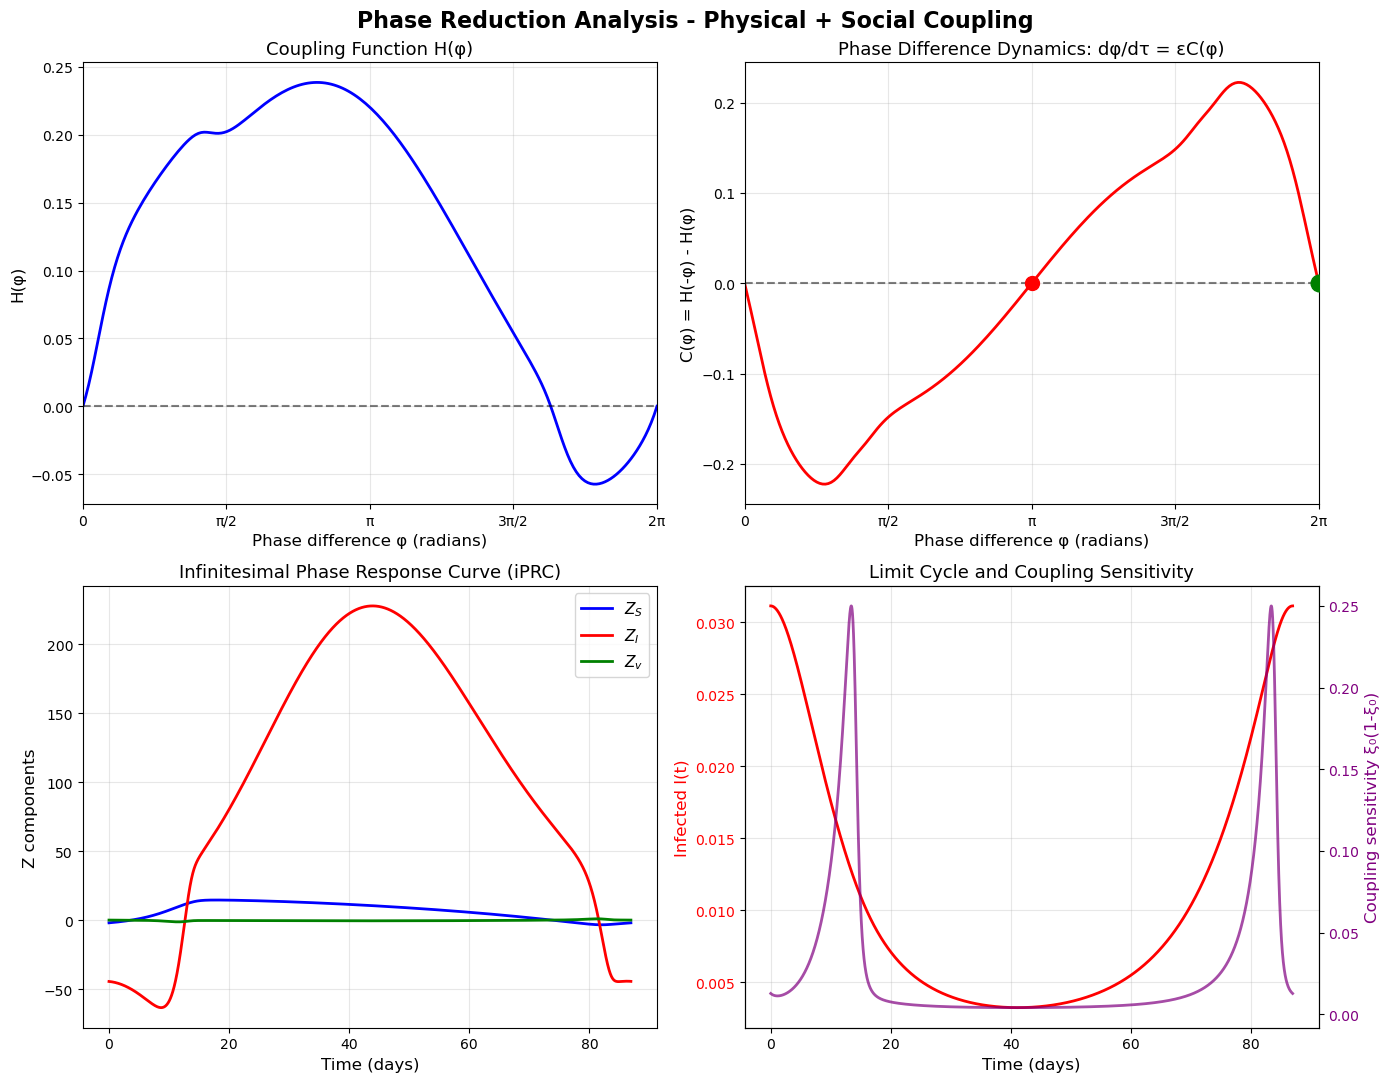


SUMMARY - PHYSICAL + SOCIAL COUPLING MODEL

Period T = 86.9100 days

Coupling terms:
  G_S = β·S·(I₁/ψ - I₂/(1-ψ))                    [Physical]
  G_I = β·S·(I₂/(1-ψ) - I₁/ψ)                    [Physical]
  G_v = κ·ξ₀(1-ξ₀)·[β(I₂/(1-ψ) - I₁/ψ) + 2θ(v₂-v₁)]  [Physical + Social]

Phase-locked states:
  φ = 180.0° : UNSTABLE
  φ = 360.0° : STABLE

Conclusion:
  → Neither synchrony nor anti-phase is stable
  → Check for other stable phase-locked states



In [3]:
"""
Phase Reduction Analysis for Physical + Social Coupling SIRv Model

This script:
1. Finds the limit cycle γ(t) for the uncoupled system
2. Computes the Jacobian A(t) = DF(γ(t)) along the cycle
3. Solves the adjoint equation to get Z(t) (iPRC)
4. Computes the coupling function H(φ) for COMBINED physical + social coupling
5. Analyzes stability of synchrony and anti-phase states
"""

import numpy as np
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from scipy.interpolate import interp1d, UnivariateSpline
from scipy.optimize import brentq
import matplotlib.pyplot as plt


# =============================================================================
# SYSTEM DEFINITION
# =============================================================================

def uncoupled_smooth_sirv(t, y, params):
    """Uncoupled smooth SIRv system (epsilon = 0)"""
    S, I, v = y
    alpha = params['alpha']
    beta = params['beta']
    gamma = params['gamma']
    eta = params['eta']
    theta = params['theta']
    kappa = params['kappa']
    rho = params['rho']
    
    dS = alpha*(1 - S - I) - beta*S*(I) - eta*v*S
    dI = -gamma*I + beta*S*(I)
    dv = -v + 1/(1 + np.exp(-kappa*(beta*I - rho - theta*(1 - 2*v))))
    
    return [dS, dI, dv]


# =============================================================================
# PARAMETERS
# =============================================================================

params = {
    'alpha': 0.01,
    'beta': 0.5,
    'gamma': 1/7,
    'eta': 1/7,
    'theta': 0.01,
    'kappa': 300,
    'rho': 0.01,
}

y0 = [0.49, 0.01, 0.01]

print("="*70)
print("PHASE REDUCTION ANALYSIS - PHYSICAL + SOCIAL COUPLING MODEL")
print("="*70)


# =============================================================================
# STEP 1: INTEGRATE PAST TRANSIENTS
# =============================================================================

t_transient = 5000

sol_transient = solve_ivp(
    lambda t, y: uncoupled_smooth_sirv(t, y, params),
    [0, t_transient],
    y0,
    method='RK45',
    rtol=1e-10,
    atol=1e-12
)

y_after_transient = sol_transient.y[:, -1]


# =============================================================================
# STEP 2: FIND THE PERIOD
# =============================================================================

t_cycle_search = 2000
dt = 0.01
t_eval = np.arange(0, t_cycle_search, dt)

sol_search = solve_ivp(
    lambda t, y: uncoupled_smooth_sirv(t, y, params),
    [0, t_cycle_search],
    y_after_transient,
    method='RK45',
    t_eval=t_eval,
    rtol=1e-10,
    atol=1e-12
)

I_data = sol_search.y[1, :]
peaks, _ = find_peaks(I_data, height=np.mean(I_data), distance=int(1/dt))

peak_times = sol_search.t[peaks]
periods = np.diff(peak_times)
T = np.mean(periods[-5:])

print(f"\nPeriod T = {T:.4f} days")


# =============================================================================
# STEP 3: EXTRACT ONE COMPLETE CYCLE
# =============================================================================

start_idx = peaks[-2]
y_cycle_start = sol_search.y[:, start_idx]

n_points = 10000
t_cycle = np.linspace(0, T, n_points)

sol_cycle = solve_ivp(
    lambda t, y: uncoupled_smooth_sirv(t, y, params),
    [0, T],
    y_cycle_start,
    method='RK45',
    t_eval=t_cycle,
    rtol=1e-12,
    atol=1e-14
)


# =============================================================================
# STEP 4: STORE THE LIMIT CYCLE
# =============================================================================

class LimitCycle:
    pass

Gamma = LimitCycle()
Gamma.t = sol_cycle.t
Gamma.S = sol_cycle.y[0, :]
Gamma.I = sol_cycle.y[1, :]
Gamma.v = sol_cycle.y[2, :]
Gamma.T = T
Gamma.y = sol_cycle.y


# =============================================================================
# STEP 5: COMPUTE THE JACOBIAN DF
# =============================================================================

import sympy as sp

S_sym, I_sym, v_sym = sp.symbols('S I v')
alpha_sym, beta_sym, gamma_sym, eta_sym = sp.symbols('alpha beta gamma eta')
theta_sym, kappa_sym, rho_sym = sp.symbols('theta kappa rho')

F1 = alpha_sym*(1 - S_sym - I_sym) - beta_sym*S_sym*(I_sym) - eta_sym*v_sym*S_sym
F2 = -gamma_sym*I_sym + beta_sym*S_sym*(I_sym)
F3 = -v_sym + 1/(1 + sp.exp(-kappa_sym*(beta_sym*I_sym - rho_sym - theta_sym*(1 - 2*v_sym))))

F = sp.Matrix([F1, F2, F3])
state = sp.Matrix([S_sym, I_sym, v_sym])

DF_symbolic = F.jacobian(state)

param_symbols = (alpha_sym, beta_sym, gamma_sym, eta_sym, theta_sym, kappa_sym, rho_sym)
all_symbols = (S_sym, I_sym, v_sym) + param_symbols

DF_func = sp.lambdify(all_symbols, DF_symbolic, modules='numpy')


def compute_DF(S, I, v, params):
    return np.array(DF_func(
        S, I, v,
        params['alpha'], params['beta'], params['gamma'], params['eta'],
        params['theta'], params['kappa'], params['rho']
    ), dtype=float)


# =============================================================================
# STEP 6: COMPUTE A(t) ALONG THE LIMIT CYCLE
# =============================================================================

n_points = len(Gamma.t)
A = np.zeros((n_points, 3, 3))

for i in range(n_points):
    A[i] = compute_DF(Gamma.S[i], Gamma.I[i], Gamma.v[i], params)


# =============================================================================
# STEP 7: COMPUTE γ'(t)
# =============================================================================

Gamma_dot = np.zeros((3, n_points))
for i in range(n_points):
    Gamma_dot[:, i] = uncoupled_smooth_sirv(Gamma.t[i], Gamma.y[:, i], params)

Gamma.S_dot = Gamma_dot[0, :]
Gamma.I_dot = Gamma_dot[1, :]
Gamma.v_dot = Gamma_dot[2, :]
Gamma.y_dot = Gamma_dot


# =============================================================================
# STEP 8: CREATE INTERPOLATION FOR A(t)
# =============================================================================

A_interp_base = interp1d(Gamma.t, A, axis=0, kind='linear', fill_value='extrapolate')

def A_interp_periodic(t):
    t_mod = np.mod(t, Gamma.T)
    return A_interp_base(t_mod)


# =============================================================================
# STEP 9: SOLVE THE ADJOINT EQUATION
# =============================================================================

def adjoint_equation_reversed(s, Z, T):
    t = T - (s % T)
    A_t = A_interp_periodic(t)
    return A_t.T @ Z

n_periods = 10
total_time = n_periods * Gamma.T

Z_initial = np.array([1.0, 1.0, 1.0])
n_points_total = n_points * n_periods
s_eval = np.linspace(0, total_time, n_points_total)

sol_adjoint = solve_ivp(
    lambda s, Z: adjoint_equation_reversed(s, Z, Gamma.T),
    [0, total_time],
    Z_initial,
    method='RK45',
    t_eval=s_eval,
    rtol=1e-10,
    atol=1e-12
)

# Extract last period
last_period_start_idx = (n_periods - 1) * n_points
Z_last_period = sol_adjoint.y[:, last_period_start_idx:]
Z_raw = Z_last_period[:, ::-1]

if Z_raw.shape[1] != n_points:
    t_raw = np.linspace(0, Gamma.T, Z_raw.shape[1])
    Z_raw_interp = np.zeros((3, n_points))
    for i in range(3):
        Z_raw_interp[i, :] = np.interp(Gamma.t, t_raw, Z_raw[i, :])
    Z_raw = Z_raw_interp


# =============================================================================
# STEP 10: VERIFY PERIODICITY
# =============================================================================

periodicity_error = np.linalg.norm(Z_raw[:, -1] - Z_raw[:, 0])
print(f"Z periodicity error: ||Z(T) - Z(0)|| = {periodicity_error:.2e}")


# =============================================================================
# STEP 11: NORMALIZE Z
# =============================================================================

omega = 2 * np.pi / Gamma.T
Z_dot_Gamma_dot = np.sum(Z_raw * Gamma_dot, axis=0)
Z_normalized = Z_raw * omega / Z_dot_Gamma_dot


# =============================================================================
# STEP 12: STORE Z(t)
# =============================================================================

class iPRC:
    pass

Z = iPRC()
Z.t = Gamma.t
Z.S = Z_normalized[0, :]
Z.I = Z_normalized[1, :]
Z.v = Z_normalized[2, :]
Z.y = Z_normalized
Z.T = Gamma.T


# =============================================================================
# STEP 13: COMPUTE ξ₀(t) AND ξ₀(1-ξ₀)
# =============================================================================

def compute_xi0_along_cycle(Gamma, params):
    kappa = params['kappa']
    beta = params['beta']
    rho = params['rho']
    theta = params['theta']
    
    q = kappa * (beta * Gamma.I  - rho - theta * (1 - 2 * Gamma.v))
    xi_0 = 1 / (1 + np.exp(-q))
    xi_0_deriv = xi_0 * (1 - xi_0)
    
    return xi_0, xi_0_deriv

xi_0, xi_0_deriv = compute_xi0_along_cycle(Gamma, params)


# =============================================================================
# STEP 14: CREATE PERIODIC INTERPOLATION FUNCTIONS
# =============================================================================

def make_periodic_interp(t, y, T):
    t_one_period = t[:-1]
    y_one_period = y[:-1]
    
    t_extended = np.concatenate([t_one_period - T, t_one_period, t_one_period + T])
    y_extended = np.concatenate([y_one_period, y_one_period, y_one_period])
    
    interp_func = interp1d(t_extended, y_extended, kind='cubic')
    
    def periodic_func(t_query):
        t_mod = np.mod(t_query, T)
        return interp_func(t_mod)
    
    return periodic_func

S_interp = make_periodic_interp(Gamma.t, Gamma.S, Gamma.T)
I_interp = make_periodic_interp(Gamma.t, Gamma.I, Gamma.T)
v_interp = make_periodic_interp(Gamma.t, Gamma.v, Gamma.T)


# =============================================================================
# STEP 15: COMPUTE H(φ) FOR PHYSICAL + SOCIAL COUPLING
# =============================================================================

def compute_H_physical_social(phi, Gamma, Z, xi_0_deriv, I_interp, v_interp, params):
    """
    Compute H(φ) for COMBINED physical + social coupling.
    
    Physical coupling (in S, I, and v equations):
        - Infection spreads between groups
        
    Social coupling (in v equation only):
        - Vaccination behavior influenced by other group
    
    G_S = β·S·(I₁ - I₂)                           [Physical only]
    G_I = β·S·(I₂ - I₁)                           [Physical only]  
    G_v = κ·ξ₀(1-ξ₀)·[β(I₂ - I₁) + 2θ(v₂ - v₁)]  [Physical + Social]
    """
    beta = params['beta']
    kappa = params['kappa']
    theta = params['theta']
    T = Gamma.T
    
    # Get shifted values: I(t+φ) and v(t+φ)
    I_shifted = I_interp(Gamma.t + phi)
    v_shifted = v_interp(Gamma.t + phi)
    
    # Physical coupling term: (I(t+φ)/(1-ψ) - I(t)/ψ)
    infection_diff = I_shifted  - Gamma.I 
    
    # Social coupling term: (v(t+φ) - v(t))
    vaccination_diff = v_shifted - Gamma.v
    
    # Compute G components
    # G_S: Physical only
    G_S = beta * Gamma.S * (-infection_diff)
    
    # G_I: Physical only
    G_I = beta * Gamma.S * infection_diff
    
    # G_v: Physical + Social
    # G_v = κ·ξ₀(1-ξ₀)·[β·(infection_diff) + 2θ·(vaccination_diff)]
    G_v = kappa * xi_0_deriv * (beta * infection_diff + 2 * theta * vaccination_diff)
    
    # Integrand: Z · G
    integrand = Z.S * G_S + Z.I * G_I + Z.v * G_v
    
    # Average over one period
    H = np.trapz(integrand, Gamma.t) / T
    
    return H


# Compute H(φ)
n_phi = 200
phi_values = np.linspace(0, Gamma.T, n_phi)
H_values = np.zeros(n_phi)

for i, phi in enumerate(phi_values):
    H_values[i] = compute_H_physical_social(phi, Gamma, Z, xi_0_deriv, I_interp, v_interp, params)

print(f"H(φ) range: [{H_values.min():.6e}, {H_values.max():.6e}]")

# Store H
class CouplingFunction:
    pass

H = CouplingFunction()
H.phi = phi_values
H.theta = 2 * np.pi * phi_values / Gamma.T
H.values = H_values
H.T = Gamma.T


# =============================================================================
# STEP 16: COMPUTE C(φ) = H(-φ) - H(φ)
# =============================================================================

C_values = np.zeros(n_phi)
for i, phi in enumerate(phi_values):
    H_minus_phi = compute_H_physical_social(-phi, Gamma, Z, xi_0_deriv, I_interp, v_interp, params)
    C_values[i] = H_minus_phi - H_values[i]

print(f"C(φ) range: [{C_values.min():.6e}, {C_values.max():.6e}]")


# =============================================================================
# STEP 17: FIND FIXED POINTS AND ANALYZE STABILITY
# =============================================================================

C_spline = UnivariateSpline(phi_values, C_values, s=0)
C_derivative = C_spline.derivative()

sign_changes = np.where(np.diff(np.sign(C_values)))[0]

print("\n" + "="*70)
print("PHASE-LOCKED STATES - PHYSICAL + SOCIAL COUPLING")
print("="*70)

fixed_points = []

for idx in sign_changes:
    phi_left = phi_values[idx]
    phi_right = phi_values[idx + 1]
    
    try:
        phi_zero = brentq(C_spline, phi_left, phi_right)
        C_prime_at_zero = C_derivative(phi_zero)
        stability = "STABLE" if C_prime_at_zero < 0 else "UNSTABLE"
        theta_zero = 2 * np.pi * phi_zero / Gamma.T
        
        fixed_points.append({
            'phi': phi_zero,
            'theta': theta_zero,
            'C_prime': C_prime_at_zero,
            'stability': stability
        })
        
        print(f"\n  φ = {phi_zero:.4f} days (θ = {np.degrees(theta_zero):.1f}°)")
        print(f"    C'(φ) = {C_prime_at_zero:.6e}")
        print(f"    {stability}")
    except Exception as e:
        pass


# =============================================================================
# STEP 18: PLOT RESULTS
# =============================================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
fig.suptitle('Phase Reduction Analysis - Physical + Social Coupling', fontsize=16, fontweight='bold')

# Plot 1: H(φ)
ax1 = axes[0, 0]
ax1.plot(H.theta, H.values, 'b-', linewidth=2)
ax1.axhline(y=0, color='k', linestyle='--', alpha=0.5)
ax1.set_xlabel('Phase difference φ (radians)', fontsize=12)
ax1.set_ylabel('H(φ)', fontsize=12)
ax1.set_title('Coupling Function H(φ)', fontsize=13)
ax1.set_xlim([0, 2*np.pi])
ax1.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
ax1.set_xticklabels(['0', 'π/2', 'π', '3π/2', '2π'])
ax1.grid(True, alpha=0.3)

# Plot 2: C(φ)
ax2 = axes[0, 1]
theta_plot = 2 * np.pi * phi_values / Gamma.T
ax2.plot(theta_plot, C_values, 'r-', linewidth=2)
ax2.axhline(y=0, color='k', linestyle='--', alpha=0.5)
ax2.set_xlabel('Phase difference φ (radians)', fontsize=12)
ax2.set_ylabel('C(φ) = H(-φ) - H(φ)', fontsize=12)
ax2.set_title('Phase Difference Dynamics: dφ/dτ = εC(φ)', fontsize=13)
ax2.set_xlim([0, 2*np.pi])
ax2.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
ax2.set_xticklabels(['0', 'π/2', 'π', '3π/2', '2π'])
ax2.grid(True, alpha=0.3)

# Mark fixed points
for fp in fixed_points:
    color = 'go' if fp['stability'] == 'STABLE' else 'ro'
    markersize = 12 if fp['stability'] == 'STABLE' else 10
    ax2.plot(fp['theta'], 0, color, markersize=markersize, zorder=5)

# Plot 3: Z components (iPRC)
ax3 = axes[1, 0]
ax3.plot(Z.t, Z.S, 'b-', linewidth=2, label='$Z_S$')
ax3.plot(Z.t, Z.I, 'r-', linewidth=2, label='$Z_I$')
ax3.plot(Z.t, Z.v, 'g-', linewidth=2, label='$Z_v$')
ax3.set_xlabel('Time (days)', fontsize=12)
ax3.set_ylabel('Z components', fontsize=12)
ax3.set_title('Infinitesimal Phase Response Curve (iPRC)', fontsize=13)
ax3.legend(fontsize=11)
ax3.grid(True, alpha=0.3)

# Plot 4: Limit cycle and coupling sensitivity
ax4 = axes[1, 1]
ax4_twin = ax4.twinx()

ax4.plot(Gamma.t, Gamma.I, 'r-', linewidth=2, label='I(t)')
ax4_twin.plot(Gamma.t, xi_0_deriv, 'purple', linewidth=2, alpha=0.7, label='ξ₀(1-ξ₀)')

ax4.set_xlabel('Time (days)', fontsize=12)
ax4.set_ylabel('Infected I(t)', fontsize=12, color='red')
ax4_twin.set_ylabel('Coupling sensitivity ξ₀(1-ξ₀)', fontsize=12, color='purple')
ax4.set_title('Limit Cycle and Coupling Sensitivity', fontsize=13)
ax4.tick_params(axis='y', labelcolor='red')
ax4_twin.tick_params(axis='y', labelcolor='purple')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('phase_reduction_physical_social_coupling.png', dpi=150, bbox_inches='tight')
plt.show()


# =============================================================================
# SUMMARY
# =============================================================================

print("\n" + "="*70)
print("SUMMARY - PHYSICAL + SOCIAL COUPLING MODEL")
print("="*70)
print(f"\nPeriod T = {Gamma.T:.4f} days")
print(f"\nCoupling terms:")
print(f"  G_S = β·S·(I₁/ψ - I₂/(1-ψ))                    [Physical]")
print(f"  G_I = β·S·(I₂/(1-ψ) - I₁/ψ)                    [Physical]")
print(f"  G_v = κ·ξ₀(1-ξ₀)·[β(I₂/(1-ψ) - I₁/ψ) + 2θ(v₂-v₁)]  [Physical + Social]")

print(f"\nPhase-locked states:")
for fp in fixed_points:
    print(f"  φ = {np.degrees(fp['theta']):.1f}° : {fp['stability']}")

# Determine overall behavior
sync_stable = any(fp['stability'] == 'STABLE' and abs(fp['theta']) < 0.1 for fp in fixed_points)
anti_stable = any(fp['stability'] == 'STABLE' and abs(fp['theta'] - np.pi) < 0.1 for fp in fixed_points)

print(f"\nConclusion:")
if sync_stable:
    print("  → Synchrony (φ = 0°) is STABLE")
    print("  → Epidemics will peak TOGETHER")
if anti_stable:
    print("  → Anti-phase (φ = 180°) is STABLE")
    print("  → Epidemics will ALTERNATE")
if not sync_stable and not anti_stable:
    print("  → Neither synchrony nor anti-phase is stable")
    print("  → Check for other stable phase-locked states")

print("\n" + "="*70)

## Confirm there is no bifurcation happening

In [ ]:
"""
Bifurcation Analysis for Physical + Social Coupling SIRv Model

Verify that there is no bifurcation for κ ∈ [300, 1000]:
- Check if synchrony (φ = 0) remains stable or unstable
- Check if anti-phase (φ = π) remains stable or unstable
"""

import numpy as np
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from scipy.interpolate import interp1d, UnivariateSpline
from scipy.optimize import brentq
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


# =============================================================================
# SYSTEM DEFINITION
# =============================================================================

def uncoupled_smooth_sirv(t, y, params):
    S, I, v = y
    alpha = params['alpha']
    beta = params['beta']
    gamma = params['gamma']
    eta = params['eta']
    theta = params['theta']
    kappa = params['kappa']
    rho = params['rho']
    
    dS = alpha*(1 - S - I) - beta*S*(I) - eta*v*S
    dI = -gamma*I + beta*S*(I)
    dv = -v + 1/(1 + np.exp(-kappa*(beta*I - rho - theta*(1 - 2*v))))
    
    return [dS, dI, dv]


# =============================================================================
# FULL ANALYSIS FUNCTION
# =============================================================================

def compute_full_analysis(params):
    """
    Compute the full phase reduction analysis for given parameters.
    Returns C'(0) and C'(π) to determine stability of sync and anti-phase.
    """
    
    # -------------------------------------------------------------------------
    # Step 1: Find limit cycle
    # -------------------------------------------------------------------------
    y0 = [0.49, 0.01, 0.01]
    t_transient = 3000
    
    sol_transient = solve_ivp(
        lambda t, y: uncoupled_smooth_sirv(t, y, params),
        [0, t_transient], y0,
        method='RK45', rtol=1e-10, atol=1e-12
    )
    y_after_transient = sol_transient.y[:, -1]
    
    # Find period
    t_cycle_search = 1500
    dt = 0.01
    t_eval = np.arange(0, t_cycle_search, dt)
    
    sol_search = solve_ivp(
        lambda t, y: uncoupled_smooth_sirv(t, y, params),
        [0, t_cycle_search], y_after_transient,
        method='RK45', t_eval=t_eval, rtol=1e-10, atol=1e-12
    )
    
    I_data = sol_search.y[1, :]
    peaks, _ = find_peaks(I_data, height=np.mean(I_data), distance=int(1/dt))
    
    if len(peaks) < 3:
        return None, None, None
    
    peak_times = sol_search.t[peaks]
    periods = np.diff(peak_times)
    T = np.mean(periods[-5:])
    
    # Extract one cycle
    start_idx = peaks[-2]
    y_cycle_start = sol_search.y[:, start_idx]
    
    n_points = 5000
    t_cycle = np.linspace(0, T, n_points)
    
    sol_cycle = solve_ivp(
        lambda t, y: uncoupled_smooth_sirv(t, y, params),
        [0, T], y_cycle_start,
        method='RK45', t_eval=t_cycle, rtol=1e-10, atol=1e-12
    )
    
    # Store limit cycle
    Gamma_t = sol_cycle.t
    Gamma_S = sol_cycle.y[0, :]
    Gamma_I = sol_cycle.y[1, :]
    Gamma_v = sol_cycle.y[2, :]
    Gamma_y = sol_cycle.y
    
    # -------------------------------------------------------------------------
    # Step 2: Compute Jacobian along cycle
    # -------------------------------------------------------------------------
    def compute_DF(S, I, v, params):
        alpha = params['alpha']
        beta = params['beta']
        gamma = params['gamma']
        eta = params['eta']
        theta = params['theta']
        kappa = params['kappa']
        rho = params['rho']
        
        q = kappa * (beta * I  - rho - theta * (1 - 2*v))
        sigma = 1 / (1 + np.exp(-q))
        sigma_prime = sigma * (1 - sigma)
        
        DF = np.array([
            [-alpha - beta*I - eta*v, -alpha - beta*S, -eta*S],
            [beta*I, -gamma + beta*S, 0],
            [0, kappa * beta  * sigma_prime, -1 + 2*kappa*theta*sigma_prime]
        ])
        return DF
    
    A = np.zeros((n_points, 3, 3))
    for i in range(n_points):
        A[i] = compute_DF(Gamma_S[i], Gamma_I[i], Gamma_v[i], params)
    
    # -------------------------------------------------------------------------
    # Step 3: Compute γ'(t)
    # -------------------------------------------------------------------------
    Gamma_dot = np.zeros((3, n_points))
    for i in range(n_points):
        Gamma_dot[:, i] = uncoupled_smooth_sirv(Gamma_t[i], Gamma_y[:, i], params)
    
    # -------------------------------------------------------------------------
    # Step 4: Solve adjoint equation
    # -------------------------------------------------------------------------
    A_interp = interp1d(Gamma_t, A, axis=0, kind='linear', fill_value='extrapolate')
    
    def A_interp_periodic(t):
        t_mod = np.mod(t, T)
        return A_interp(t_mod)
    
    def adjoint_reversed(s, Z):
        t = T - (s % T)
        A_t = A_interp_periodic(t)
        return A_t.T @ Z
    
    n_periods = 10
    total_time = n_periods * T
    Z_initial = np.array([1.0, 1.0, 1.0])
    
    n_points_total = n_points * n_periods
    s_eval = np.linspace(0, total_time, n_points_total)
    
    sol_adjoint = solve_ivp(
        adjoint_reversed, [0, total_time], Z_initial,
        method='RK45', t_eval=s_eval, rtol=1e-10, atol=1e-12
    )
    
    # Extract last period
    last_period_start_idx = (n_periods - 1) * n_points
    Z_raw = sol_adjoint.y[:, last_period_start_idx:]
    Z_raw = Z_raw[:, ::-1]
    
    if Z_raw.shape[1] != n_points:
        t_raw = np.linspace(0, T, Z_raw.shape[1])
        Z_raw_interp = np.zeros((3, n_points))
        for i in range(3):
            Z_raw_interp[i, :] = np.interp(Gamma_t, t_raw, Z_raw[i, :])
        Z_raw = Z_raw_interp
    
    # Normalize
    omega = 2 * np.pi / T
    Z_dot_Gamma_dot = np.sum(Z_raw * Gamma_dot, axis=0)
    Z_normalized = Z_raw * omega / Z_dot_Gamma_dot
    
    Z_S = Z_normalized[0, :]
    Z_I = Z_normalized[1, :]
    Z_v = Z_normalized[2, :]
    
    # -------------------------------------------------------------------------
    # Step 5: Compute coupling terms
    # -------------------------------------------------------------------------
    kappa_val = params['kappa']
    beta_val = params['beta']
    rho_val = params['rho']
    theta_val = params['theta']
    
    # ξ₀(t) and ξ₀(1-ξ₀)
    q = kappa_val * (beta_val * Gamma_I  - rho_val - theta_val * (1 - 2 * Gamma_v))
    xi_0 = 1 / (1 + np.exp(-q))
    xi_0_deriv = xi_0 * (1 - xi_0)
    
    # Periodic interpolators
    def make_periodic_interp(t, y, T):
        t_ext = np.concatenate([t[:-1] - T, t[:-1], t[:-1] + T])
        y_ext = np.concatenate([y[:-1], y[:-1], y[:-1]])
        interp_func = interp1d(t_ext, y_ext, kind='cubic')
        return lambda t_q: interp_func(np.mod(t_q, T))
    
    I_interp = make_periodic_interp(Gamma_t, Gamma_I, T)
    v_interp = make_periodic_interp(Gamma_t, Gamma_v, T)
    
    # -------------------------------------------------------------------------
    # Step 6: Compute H(φ) for PHYSICAL + SOCIAL coupling
    # -------------------------------------------------------------------------
    def compute_H(phi):
        I_shifted = I_interp(Gamma_t + phi)
        v_shifted = v_interp(Gamma_t + phi)
        
        # Physical coupling term
        infection_diff = I_shifted  - Gamma_I 
        
        # Social coupling term
        vaccination_diff = v_shifted - Gamma_v
        
        # G components
        G_S = beta_val * Gamma_S * (-infection_diff)
        G_I = beta_val * Gamma_S * infection_diff
        G_v = kappa_val * xi_0_deriv * (beta_val * infection_diff + 2 * theta_val * vaccination_diff)
        
        integrand = Z_S * G_S + Z_I * G_I + Z_v * G_v
        H = np.trapz(integrand, Gamma_t) / T
        return H
    
    # Compute C(φ) = H(-φ) - H(φ)
    n_phi = 100
    phi_values = np.linspace(0, T, n_phi)
    C_values = np.zeros(n_phi)
    
    for i, phi in enumerate(phi_values):
        H_plus = compute_H(phi)
        H_minus = compute_H(-phi)
        C_values[i] = H_minus - H_plus
    
    # -------------------------------------------------------------------------
    # Step 7: Find C'(0) and C'(π)
    # -------------------------------------------------------------------------
    C_spline = UnivariateSpline(phi_values, C_values, s=0)
    C_derivative = C_spline.derivative()
    
    C_prime_0 = C_derivative(0)
    C_prime_pi = C_derivative(T / 2)
    
    return C_prime_0, C_prime_pi, T


# =============================================================================
# BIFURCATION ANALYSIS
# =============================================================================

print("="*70)
print("BIFURCATION ANALYSIS - PHYSICAL + SOCIAL COUPLING")
print("="*70)

# Base parameters
base_params = {
    'alpha': 0.01,
    'beta': 0.5,
    'gamma': 1/7,
    'eta': 1/7,
    'theta': 0.01,
    'kappa': 300,
    'rho': 0.01,
    'psi': 0.5
}

# κ values: 25 apart from 300-500, 50 apart from 500-1000
kappa_values_1 = np.arange(300, 500, 25)
kappa_values_2 = np.arange(500, 1001, 50)
kappa_values = np.concatenate([kappa_values_1, kappa_values_2])

print(f"\nTesting {len(kappa_values)} values of κ: {kappa_values[0]} to {kappa_values[-1]}")

# Storage
C_prime_0_list = []
C_prime_pi_list = []
T_list = []

for kappa in kappa_values:
    params = base_params.copy()
    params['kappa'] = kappa
    
    print(f"  κ = {kappa}...", end=" ")
    
    try:
        C_prime_0, C_prime_pi, T = compute_full_analysis(params)
        C_prime_0_list.append(C_prime_0)
        C_prime_pi_list.append(C_prime_pi)
        T_list.append(T)
        
        sync_stable = "stable" if C_prime_0 < 0 else "unstable"
        anti_stable = "stable" if C_prime_pi < 0 else "unstable"
        print(f"sync: {sync_stable}, anti-phase: {anti_stable}")
    except Exception as e:
        print(f"FAILED: {e}")
        C_prime_0_list.append(np.nan)
        C_prime_pi_list.append(np.nan)
        T_list.append(np.nan)

C_prime_0_arr = np.array(C_prime_0_list)
C_prime_pi_arr = np.array(C_prime_pi_list)
T_arr = np.array(T_list)


# =============================================================================
# PLOT BIFURCATION DIAGRAM
# =============================================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Bifurcation Diagram: Physical + Social Coupling", fontsize=16, fontweight='bold')

# Plot 1: C'(0) vs κ
ax1 = axes[0, 0]
ax1.plot(kappa_values, C_prime_0_arr, 'bo-', linewidth=2, markersize=6)
ax1.axhline(y=0, color='k', linestyle='--', linewidth=1)
ax1.fill_between(kappa_values, C_prime_0_arr, 0, 
                  where=(C_prime_0_arr < 0), alpha=0.3, color='green', label='Stable')
ax1.fill_between(kappa_values, C_prime_0_arr, 0,
                  where=(C_prime_0_arr > 0), alpha=0.3, color='red', label='Unstable')
ax1.set_xlabel('κ (payoff sensitivity)', fontsize=12)
ax1.set_ylabel("C'(0)", fontsize=12)
ax1.set_title("Synchrony (φ = 0): C'(0) < 0 → STABLE", fontsize=12)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: C'(π) vs κ
ax2 = axes[0, 1]
ax2.plot(kappa_values, C_prime_pi_arr, 'ro-', linewidth=2, markersize=6)
ax2.axhline(y=0, color='k', linestyle='--', linewidth=1)
ax2.fill_between(kappa_values, C_prime_pi_arr, 0,
                  where=(C_prime_pi_arr < 0), alpha=0.3, color='green', label='Stable')
ax2.fill_between(kappa_values, C_prime_pi_arr, 0,
                  where=(C_prime_pi_arr > 0), alpha=0.3, color='red', label='Unstable')
ax2.set_xlabel('κ (payoff sensitivity)', fontsize=12)
ax2.set_ylabel("C'(π)", fontsize=12)
ax2.set_title("Anti-phase (φ = π): C'(π) < 0 → STABLE", fontsize=12)
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Both on same plot
ax3 = axes[1, 0]
ax3.plot(kappa_values, C_prime_0_arr, 'b-', linewidth=2, marker='o', markersize=5, label="C'(0) - Synchrony")
ax3.plot(kappa_values, C_prime_pi_arr, 'r-', linewidth=2, marker='s', markersize=5, label="C'(π) - Anti-phase")
ax3.axhline(y=0, color='k', linestyle='--', linewidth=1)
ax3.set_xlabel('κ (payoff sensitivity)', fontsize=12)
ax3.set_ylabel("C'(φ)", fontsize=12)
ax3.set_title("Comparison of C'(0) and C'(π)", fontsize=12)
ax3.legend()
ax3.grid(True, alpha=0.3)

# Plot 4: Period vs κ
ax4 = axes[1, 1]
ax4.plot(kappa_values, T_arr, 'g-', linewidth=2, marker='d', markersize=5)
ax4.set_xlabel('κ (payoff sensitivity)', fontsize=12)
ax4.set_ylabel("Period T (days)", fontsize=12)
ax4.set_title("Limit Cycle Period vs κ", fontsize=12)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('bifurcation_diagram_physical_social.png', dpi=150)
plt.show()


# =============================================================================
# SUMMARY
# =============================================================================

print("\n" + "="*70)
print("BIFURCATION ANALYSIS SUMMARY - PHYSICAL + SOCIAL COUPLING")
print("="*70)

# Check for sign changes
sync_always_stable = np.all(C_prime_0_arr < 0)
sync_always_unstable = np.all(C_prime_0_arr > 0)
anti_always_stable = np.all(C_prime_pi_arr < 0)
anti_always_unstable = np.all(C_prime_pi_arr > 0)

print(f"\nκ range tested: {kappa_values.min()} to {kappa_values.max()}")

print(f"\nSynchrony (φ = 0):")
print(f"  C'(0) range: [{C_prime_0_arr.min():.6e}, {C_prime_0_arr.max():.6e}]")
if sync_always_stable:
    print(f"  → ALWAYS STABLE (C'(0) < 0 for all κ)")
elif sync_always_unstable:
    print(f"  → ALWAYS UNSTABLE (C'(0) > 0 for all κ)")
else:
    print(f"  → BIFURCATION DETECTED")

print(f"\nAnti-phase (φ = π):")
print(f"  C'(π) range: [{C_prime_pi_arr.min():.6e}, {C_prime_pi_arr.max():.6e}]")
if anti_always_stable:
    print(f"  → ALWAYS STABLE (C'(π) < 0 for all κ)")
elif anti_always_unstable:
    print(f"  → ALWAYS UNSTABLE (C'(π) > 0 for all κ)")
else:
    print(f"  → BIFURCATION DETECTED")

# Final verdict
print("\n" + "="*70)
if (sync_always_stable or sync_always_unstable) and (anti_always_stable or anti_always_unstable):
    print("✓ NO BIFURCATION in the tested κ range!")
    print(f"  Synchrony: {'STABLE' if sync_always_stable else 'UNSTABLE'} for all κ ∈ [300, 1000]")
    print(f"  Anti-phase: {'STABLE' if anti_always_stable else 'UNSTABLE'} for all κ ∈ [300, 1000]")
else:
    print("⚠ BIFURCATION DETECTED!")
    # Find approximate bifurcation points
    if not (sync_always_stable or sync_always_unstable):
        sign_changes = np.where(np.diff(np.sign(C_prime_0_arr)))[0]
        for idx in sign_changes:
            print(f"  Synchrony changes stability near κ ≈ {kappa_values[idx]}")
    if not (anti_always_stable or anti_always_unstable):
        sign_changes = np.where(np.diff(np.sign(C_prime_pi_arr)))[0]
        for idx in sign_changes:
            print(f"  Anti-phase changes stability near κ ≈ {kappa_values[idx]}")
print("="*70)

BIFURCATION ANALYSIS - PHYSICAL + SOCIAL COUPLING

Testing 19 values of κ: 300 to 1000
  κ = 300... sync: stable, anti-phase: unstable
  κ = 325... sync: stable, anti-phase: unstable
  κ = 350... sync: stable, anti-phase: unstable
  κ = 375... sync: stable, anti-phase: unstable
  κ = 400... sync: stable, anti-phase: unstable
  κ = 425... sync: stable, anti-phase: unstable
  κ = 450... 